# Tìm siêu tham số và đánh giá: LSTM

1. **Tìm siêu tham số** bằng Optuna (TPE sampler + Median pruner) trên tập feature đã chọn. Mục tiêu là **val MAE** (thang đã chuẩn hóa, trung bình 2 target). Ngân sách (`ft.BUDGET`) **giống hệt** cho LSTM và GAT-GRU: cùng số trial, cùng số epoch tối đa, cùng early stopping, cùng seed của sampler.
2. **Huấn luyện lại** cấu hình tốt nhất với 5 seed, rồi đánh giá **một lần** trên test ở đơn vị gốc (MAE/RMSE), báo cáo trung bình ± độ lệch chuẩn qua các seed.
3. **Lưu** `lstm_predictions_test.npz` theo quy ước của `forecast_metrics.py`, cho notebook so sánh.

Không gian tìm kiếm (horizon h = 6 cố định):

| Siêu tham số | Giá trị |
|---|---|
| window w | {6, 12, 18} bước |
| dropout | [0; 0,3] |
| learning rate | [1e-4; 3e-3] (log) |
| batch size | {64, 128, 256} |
| hidden | {32, 64, 128} |
| số lớp LSTM | {1, 2, 3} |
| chế độ | `per_service` (trọng số chung, mỗi service một chuỗi) / `joint` (ghép cả 11 service) |

**Dữ liệu:** các run trong `math-load-testing/results/` (kịch bản nhpp, mmpp, pareto, onoff, thu khi HPA bật). Split dùng chung `modeling-common/splits_math.json`, đầu ra `processed_math/`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

COMMON = (Path('..') / 'modeling-common').resolve()   # code dùng chung cho GAT-GRU và LSTM
sys.path.insert(0, str(COMMON))
import forecast_data as fd

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

import forecast_metrics as fm
import forecast_torch as ft
import torch

In [2]:
TAG = '_math'                     # dataset math-load-testing, giống notebook tiền xử lý
PROCESSED = Path(f'processed{TAG}') if (Path(f'processed{TAG}') / 'runs_raw.npz').exists() else Path(f'processed{TAG}_demo')
DEMO = PROCESSED.name.endswith('_demo')
MODEL = 'lstm'
B = ft.DEMO_BUDGET if DEMO else ft.BUDGET
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
runs, meta = fd.load_runs_npz(PROCESSED / 'runs_raw.npz')
splits = meta['splits']
edges = [tuple(e) for e in meta['edges']]
sel_path = PROCESSED / 'selected_features.json'
if sel_path.exists():
    sel = json.loads(sel_path.read_text())
else:
    print('⚠️ Chưa chạy feature_selection: dùng mọi feature ứng viên')
    sel = {'node': fd.NF, 'edge': fd.EF if MODEL == 'gatgru' else []}
data = ft.Data(runs, splits, sel['node'], sel['edge'] if MODEL == 'gatgru' else None)
print('device:', DEVICE, '| budget:', B)
print('node features:', data.node_feats)
print('edge features:', data.edge_feats)

device: cpu | budget: {'n_trials': 40, 'search_seed': 42, 'final_seeds': (0, 1, 2, 3, 4), 'importance_repeats': 5}
node features: ['rps_in', 'rps_in_delta', 'rps_per_replica', 'latency_p50_ms', 'latency_p95_ms', 'cpu_cores', 'cpu_util_request', 'cpu_throttle_ratio', 'cpu_sidecar_cores', 'mem_mib', 'net_rx_kBps', 'net_tx_kBps', 'replicas']
edge features: []


## 1. Optuna

In [3]:
study = ft.run_optuna(MODEL, data, edges, n_trials=B['n_trials'], seed=B['search_seed'], device=DEVICE,
                      max_epochs=B.get('max_epochs'))
trials = study.trials_dataframe(attrs=('number', 'value', 'params', 'state'))
print('best val MAE (scaled):', round(study.best_value, 4))
print('best params:', study.best_params)
trials.sort_values('value').head(10)

[I 2026-10-09 20:21:25,229] A new study created in memory with name: no-name-f2f4bb12-7783-40c6-a0bc-e5b8dfd85fdd
[I 2026-10-09 20:29:08,733] Trial 0 finished with value: 0.1403716802597046 and parameters: {'window': 12, 'dropout': 0.17959754525911098, 'lr': 0.0001700037298921101, 'batch_size': 256, 'hidden': 64, 'layers': 3, 'mode': 'per_service'}. Best is trial 0 with value: 0.1403716802597046.
[I 2026-10-09 20:34:14,333] Trial 1 finished with value: 0.11442534625530243 and parameters: {'window': 18, 'dropout': 0.15742692948967135, 'lr': 0.0004345454109729479, 'batch_size': 128, 'hidden': 128, 'layers': 3, 'mode': 'joint'}. Best is trial 1 with value: 0.11442534625530243.
[I 2026-10-09 20:37:34,107] Trial 2 finished with value: 0.12371458113193512 and parameters: {'window': 18, 'dropout': 0.051157237106187456, 'lr': 0.00012476394272569445, 'batch_size': 128, 'hidden': 128, 'layers': 2, 'mode': 'joint'}. Best is trial 1 with value: 0.11442534625530243.
[I 2026-10-09 20:39:23,337] Tria

best val MAE (scaled): 0.1102
best params: {'window': 18, 'dropout': 0.06815424210940646, 'lr': 0.0012076024905616797, 'batch_size': 64, 'hidden': 128, 'layers': 2, 'mode': 'joint'}


,number,value,params_batch_size,params_dropout,params_hidden,params_layers,params_lr,params_mode,params_window,state
32,32,0.110227,64,0.068154,128,2,0.001208,joint,18,COMPLETE
38,38,0.110353,64,0.051542,128,2,0.002434,joint,18,COMPLETE
26,26,0.110431,64,0.096585,128,2,0.001113,joint,18,COMPLETE
17,17,0.110655,128,0.119082,128,2,0.000885,joint,18,COMPLETE
11,11,0.110949,256,0.293591,128,2,0.000798,joint,18,COMPLETE
30,30,0.111029,64,0.016803,128,2,0.000690,joint,18,COMPLETE
25,25,0.111270,64,0.102010,128,2,0.000821,joint,18,COMPLETE
39,39,0.111650,64,0.092984,128,1,0.002574,joint,18,COMPLETE
12,12,0.111768,128,0.094894,128,3,0.001638,joint,18,COMPLETE
34,34,0.111805,128,0.125710,128,2,0.001060,joint,18,COMPLETE


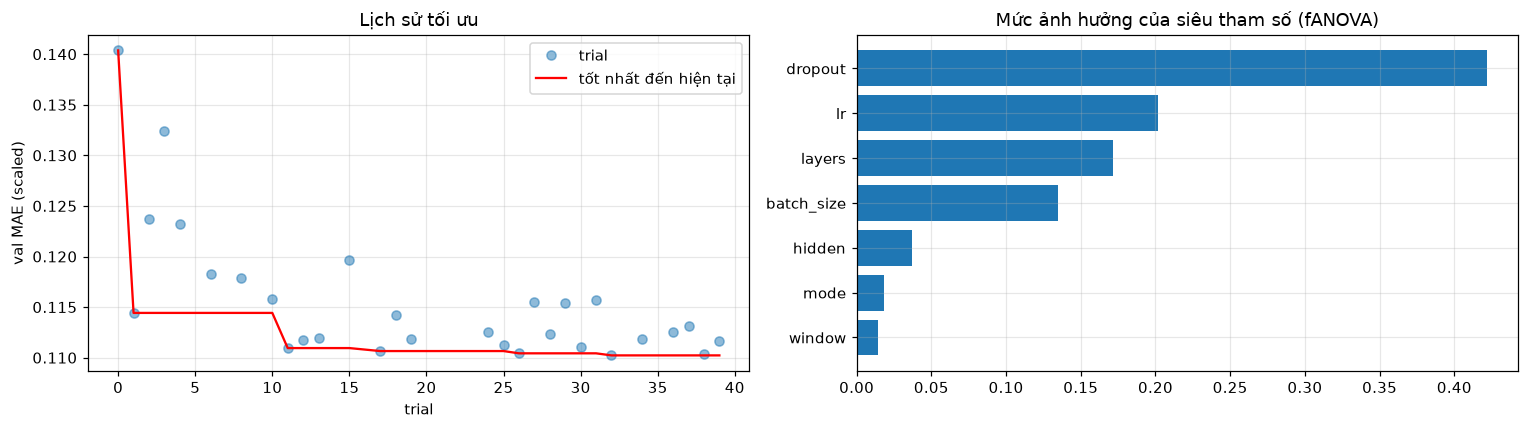

In [4]:
done = trials[trials.state == 'COMPLETE'].sort_values('number')
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(done.number, done.value, 'o', alpha=0.5, label='trial')
axes[0].plot(done.number, done.value.cummin(), 'r-', label='tốt nhất đến hiện tại')
axes[0].set_xlabel('trial')
axes[0].set_ylabel('val MAE (scaled)')
axes[0].legend()
axes[0].set_title('Lịch sử tối ưu')
try:
    import optuna
    imp = optuna.importance.get_param_importances(study)
    axes[1].barh(list(imp)[::-1], list(imp.values())[::-1])
    axes[1].set_title('Mức ảnh hưởng của siêu tham số (fANOVA)')
except Exception as exc:
    axes[1].text(0.1, 0.5, f'không tính được: {exc}', wrap=True)
fig.tight_layout()
plt.show()

## 2. Huấn luyện lại với nhiều seed và đánh giá trên test

In [5]:
cfg = ft.study_config(study, MODEL, bool(data.edge_feats))
if B.get('max_epochs'):
    cfg['max_epochs'] = B['max_epochs']
preds, test_w, models, meta_m = ft.final_runs(MODEL, cfg, data, edges, seeds=B['final_seeds'], device=DEVICE)
meta_m['demo'] = DEMO
fm.save_predictions(PROCESSED / f'{MODEL}_predictions_test.npz', preds, test_w['Y_raw'], test_w['Y_last'],
                    test_w['info'], meta_m)
ft.save_model(PROCESSED / f'{MODEL}_model.pt', models[0], meta_m)
(PROCESSED / f'{MODEL}_best_config.json').write_text(json.dumps(cfg, indent=1))
print(f"params: {meta_m['n_params']:,} | inference 1 window: {meta_m['inference_ms']:.2f} ms | test windows: {len(test_w['X'])}")

d = fm.load_predictions(PROCESSED / f'{MODEL}_predictions_test.npz')
summary, _, _ = fm.seed_summary(d, fd.TARGETS, MODEL.upper())
pers = fm.error_table(fm.persistence(d), d['Y_true'], fd.TARGETS).round(4).astype(str)
pers.insert(0, 'model', 'persistence')
pd.concat([summary, pers])

params: 311,472 | inference 1 window: 4.30 ms | test windows: 611


,model,MAE,RMSE,under_MAE,over_MAE
target,,,,,
rps_in,LSTM,0.9741 ± 0.0194,2.9419 ± 0.0497,0.5498 ± 0.0145,0.4243 ± 0.0245
cpu_cores,LSTM,0.0129 ± 0.0001,0.0371 ± 0.0005,0.0071 ± 0.0002,0.0058 ± 0.0002
rps_in,persistence,1.186,3.4151,0.6005,0.5855
cpu_cores,persistence,0.0199,0.0609,0.0102,0.0096


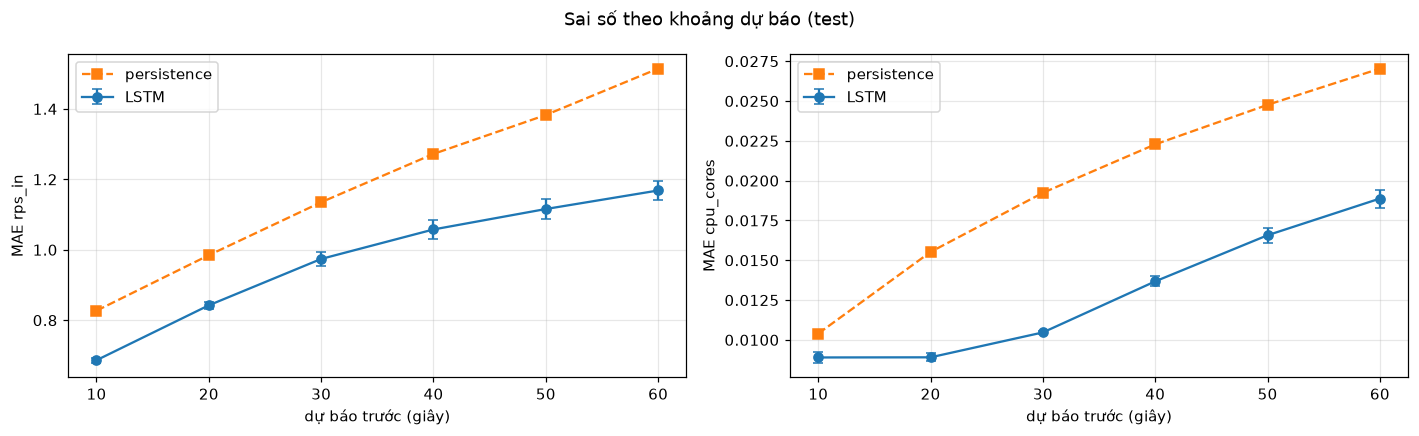

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k, t in enumerate(fd.TARGETS):
    h = np.arange(1, fd.HORIZON + 1) * fd.STEP_SEC
    per_seed = np.stack([fm.by_horizon(d['Y_pred'][s], d['Y_true'], k) for s in range(len(d['Y_pred']))])
    axes[k].errorbar(h, per_seed.mean(0), yerr=per_seed.std(0), marker='o', capsize=3, label=MODEL.upper())
    axes[k].plot(h, fm.by_horizon(fm.persistence(d), d['Y_true'], k), 's--', label='persistence')
    axes[k].set_xlabel('dự báo trước (giây)')
    axes[k].set_ylabel(f'MAE {t}')
    axes[k].legend()
fig.suptitle('Sai số theo khoảng dự báo (test)')
fig.tight_layout()
plt.show()

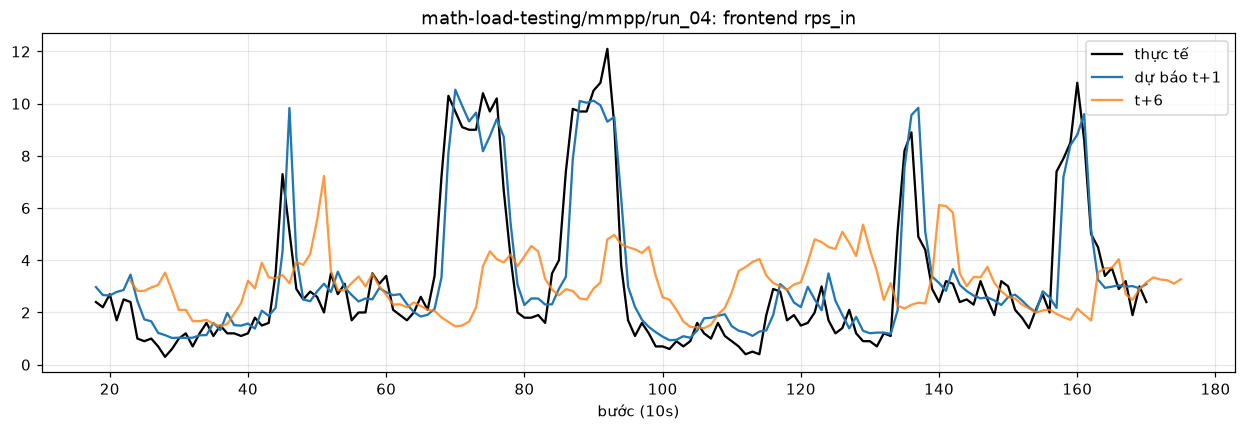

In [7]:
# Ví dụ dự báo frontend rps_in trên run test đầu tiên (seed 0, bước dự báo t+1 và t+6)
f = fd.SERVICES.index('frontend')
key = d['info'][0, 0]
m = d['info'][:, 0] == key
t = d['info'][m, 2].astype(int)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(t, d['Y_true'][m, 0, f, 0], 'k-', lw=1.5, label='thực tế')
ax.plot(t, d['Y_pred'][0][m, 0, f, 0], label='dự báo t+1')
ax.plot(t + fd.HORIZON - 1, d['Y_pred'][0][m, -1, f, 0], label=f't+{fd.HORIZON}', alpha=0.8)
ax.set_title(f'{key}: frontend rps_in')
ax.set_xlabel('bước (10s)')
ax.legend()
plt.show()